# Diniz Ch.5 — RLS FIR, DFE and QAM equalizers


## 1. Setup

In [1]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Severe channel and colored noise

In [2]:
from adsp.experiments.diniz import SEVERE_CHANNEL, QAM_CHANNEL

n_samples, n_trials, seed = 200, 30, 5020
make_data = partial(data.equalization, n_samples, h=SEVERE_CHANNEL, decision_delay=19, symbol_kind="bpsk", prefix=51,
                    noise_var=10**-1.5, noise_exponent=1.5)
models = {
  "RLS FIR 51 taps": partial(af.RLS, filter_order=50, lam=0.99, delta=0.01),
  "RLS DFE 30 FF + 21 FB": partial(ae.RlsDfe, n_ff=30, n_fb=21, lam=0.99, delta=0.01),
}
results = training.compare(models, make_data, n_trials=n_trials, seed=seed)

## 3. FIR/DFE results

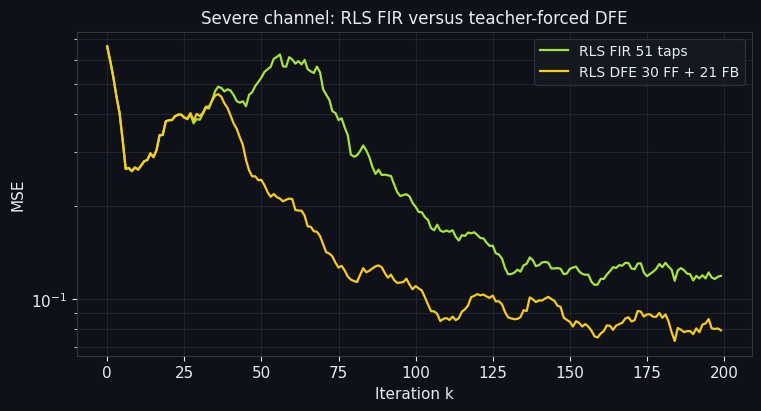

Model                                  Tail MSE     Tail MSD  Update rate
RLS FIR 51 taps                         0.12262            —            —
RLS DFE 30 FF + 21 FB                  0.082722            —            —


In [3]:
plot.learning(results, scale="log", window=11, title="Severe channel: RLS FIR versus teacher-forced DFE")
plot.show()
training.summary(results, tail=50)

## 4. QAM data and RLS factories

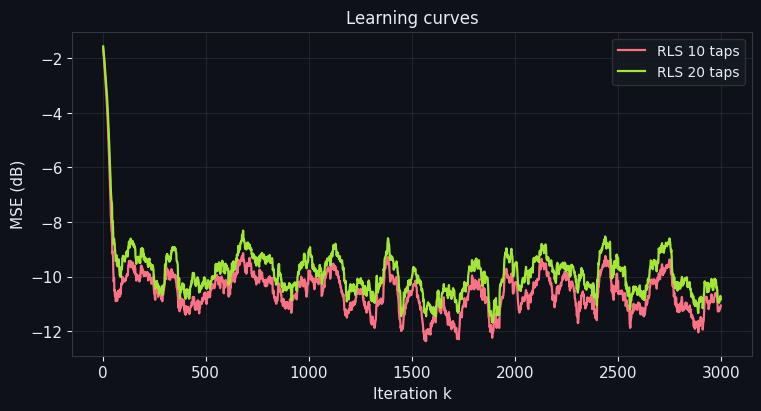

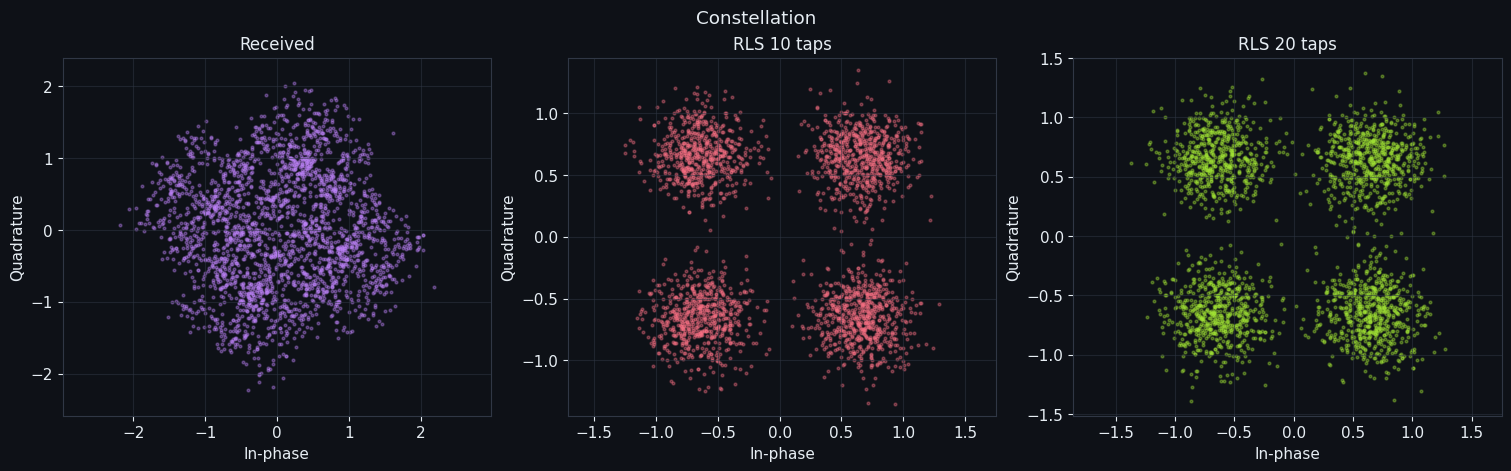

Model                                  Tail MSE     Tail MSD  Update rate
RLS 10 taps                            0.077318            —            —
RLS 20 taps                            0.091899            —            —


In [4]:
make_qam = partial(data.equalization, 3000, h=QAM_CHANNEL, decision_delay=2, symbol_kind="qam4", symbol_energy=1.0,
                   snr_linear=20.0)
qam_models = {
  f"RLS {n_taps} taps": partial(af.RLS, filter_order=n_taps - 1, lam=0.97, delta=0.1)
  for n_taps in (10, 20)
}
qam_results = training.compare(qam_models, make_qam, n_trials=1, seed=seed)
plot.learning(qam_results, window=64)
plot.show()
r10, r20 = (qam_results[name].representative for name in qam_results)
plot.constellation({"Received": r10.x, "RLS 10 taps": r10.y, "RLS 20 taps": r20.y}, start=500)
plot.show()
training.summary(qam_results)